C:\Users\admin\AppData\Local\Temp\ipykernel_20284\3865666766.py:31: RuntimeWarning: overflow encountered in exp
  return K / (1 + ((K / P0_malthus) - 1) * np.exp(-r * (x - years[0])))
C:\Users\admin\AppData\Local\Temp\ipykernel_20284\3865666766.py:31: RuntimeWarning: overflow encountered in multiply
  return K / (1 + ((K / P0_malthus) - 1) * np.exp(-r * (x - years[0])))


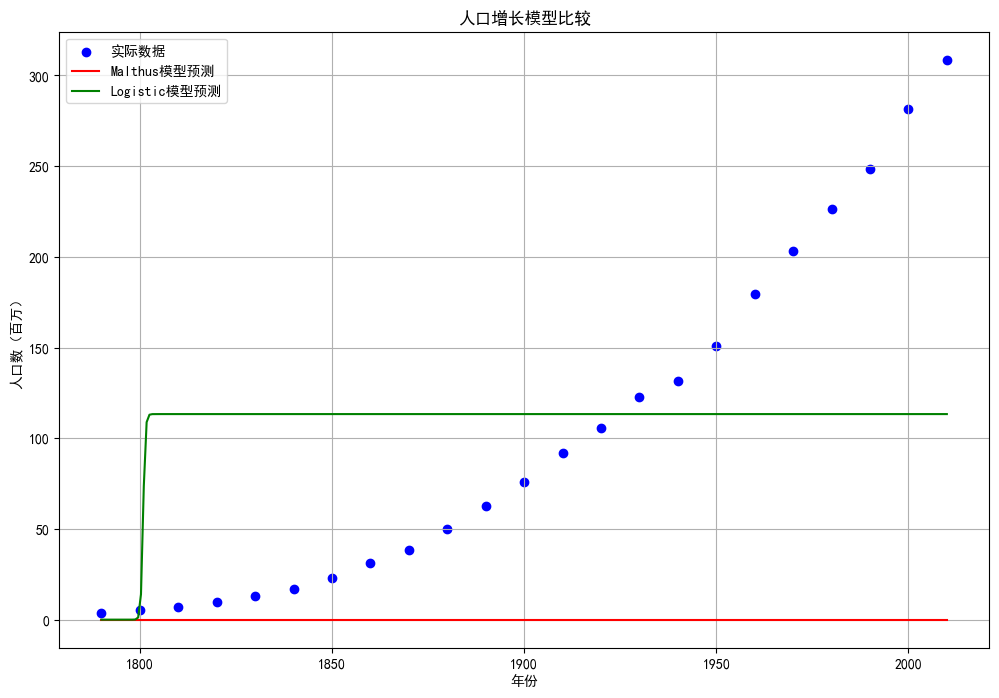

In [3]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']  #用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  #用来正常显示负号
# 加载数据
data_path = 'population.csv'
population_data = pd.read_csv(data_path)

# 数据预处理
years = population_data['YEAR'].values
populations = population_data['POPULATION/million'].values
log_populations = np.log(populations)  # 对人口数量取对数

# Malthus模型的线性拟合
def linear_model(x, a, b):
    return a * x + b

# 使用线性模型拟合对数化的人口数据
params, covariance = curve_fit(linear_model, years, log_populations)
slope = params[0]  # 增长率r
intercept = params[1]  # 初始人口对数

# 计算Malthus模型参数
r_malthus = slope
P0_malthus = np.exp(intercept)

# Logistic模型定义
def logistic_model(x, r, K):
    return K / (1 + ((K / P0_malthus) - 1) * np.exp(-r * (x - years[0])))

# 使用非线性拟合求解Logistic模型参数
logistic_params, logistic_cov = curve_fit(logistic_model, years, populations, maxfev=10000)
r_logistic = logistic_params[0]
K_logistic = logistic_params[1]

# 生成预测年份数据
prediction_years = np.linspace(min(years), max(years), 300)

# 使用Malthus模型进行人口预测
malthus_predictions = P0_malthus * np.exp(r_malthus * (prediction_years - years[0]))

# 使用Logistic模型进行人口预测
logistic_predictions = logistic_model(prediction_years, r_logistic, K_logistic)

# 绘制结果对比图
plt.figure(figsize=(12, 8))
plt.scatter(years, populations, color='blue', label='实际数据')
plt.plot(prediction_years, malthus_predictions, color='red', label='Malthus模型预测')
plt.plot(prediction_years, logistic_predictions, color='green', label='Logistic模型预测')
plt.title('人口增长模型比较')
plt.xlabel('年份')
plt.ylabel('人口数（百万）')
plt.legend()
plt.grid(True)
plt.show()


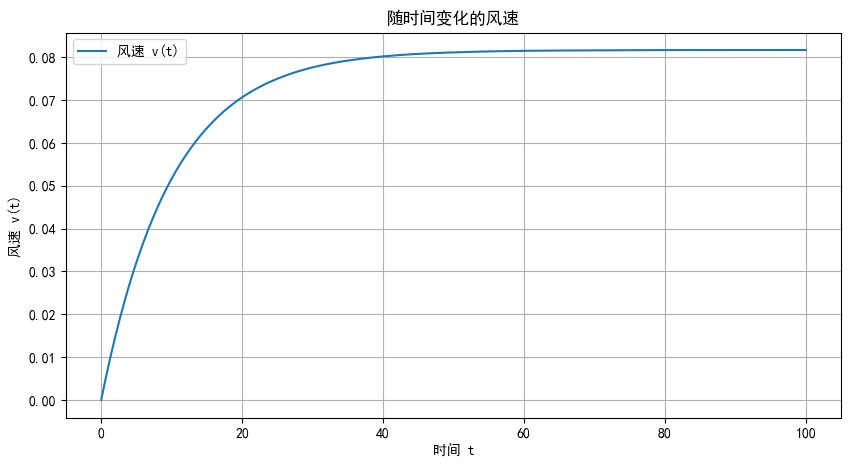

In [4]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# 参数定义
rho = 1.225  # 空气密度, kg/m^3
beta = 0.01  # 气压梯度系数
k = 0.1      # 摩擦系数
g = 0        # 重力加速度, m/s^2 (水平运动忽略)

# 微分方程
def model(t, v):
    dp_dx = -beta  # 气压梯度
    dv_dt = -(1/rho) * dp_dx - k * v + g
    return dv_dt

# 初始条件和时间间隔
v0 = 0  # 初始速度
t_span = (0, 100)  # 时间范围
t_eval = np.linspace(t_span[0], t_span[1], 300)  # 时间点

# 解微分方程
sol = solve_ivp(model, t_span, [v0], t_eval=t_eval, method='RK45')

# 绘图
plt.figure(figsize=(10, 5))
plt.plot(sol.t, sol.y[0], label='风速 v(t)')
plt.title('随时间变化的风速')
plt.xlabel('时间 t')
plt.ylabel('风速 v(t)')
plt.legend()
plt.grid(True)
plt.show()

